In [ ]:
# 1.IMPORT LIBRARIES AND LOAD DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("/content/sales_data.csv")

# Display first 5 rows
print(df.head())

  invoice_no customer_id  category  quantity    price invoice_date  \
0    I138884     C241288  Clothing         5  1500.40   05-08-2022   
1    I317333     C111565     Shoes         3  1800.51   12-12-2021   
2    I127801     C266599  Clothing         1   300.08   09-11-2021   
3    I173702     C988172     Shoes         5  3000.85   16-05-2021   
4    I337046     C189076     Books         4    60.60   24-10-2021   

    shopping_mall  
0          Kanyon  
1  Forum Istanbul  
2       Metrocity  
3    Metropol AVM  
4          Kanyon  


In [ ]:
# 2.UNDERSTAND THE DATASET

# Display first 5 rows
print(df.head())

# Display last 5 rows
print(df.tail())

# Check number of rows and columns
print(df.shape)

# Display column names
print(df.columns)

# Display dataset information
df.info()

# Display statistical summary
print(df.describe())

# Check data types
print(df.dtypes)

  invoice_no customer_id  category  quantity    price invoice_date  \
0    I138884     C241288  Clothing         5  1500.40   05-08-2022   
1    I317333     C111565     Shoes         3  1800.51   12-12-2021   
2    I127801     C266599  Clothing         1   300.08   09-11-2021   
3    I173702     C988172     Shoes         5  3000.85   16-05-2021   
4    I337046     C189076     Books         4    60.60   24-10-2021   

    shopping_mall  
0          Kanyon  
1  Forum Istanbul  
2       Metrocity  
3    Metropol AVM  
4          Kanyon  
      invoice_no customer_id         category  quantity    price invoice_date  \
99452    I219422     C441542         Souvenir         5    58.65   21-09-2022   
99453    I325143     C569580  Food & Beverage         2    10.46   22-09-2021   
99454    I824010     C103292  Food & Beverage         2    10.46   28-03-2021   
99455    I702964     C800631       Technology         4  4200.00   16-03-2021   
99456    I232867     C273973         Souvenir         

In [ ]:
# 3.DATA CLEANING

# Check missing values in each column
print(df.isnull().sum())

# Count total missing values
print(df.isnull().sum().sum())

invoice_no       0
customer_id      0
category         0
quantity         0
price            0
invoice_date     0
shopping_mall    0
dtype: int64
0


In [ ]:
# Count duplicate rows
print(df.duplicated().sum())

0


In [ ]:
df = df.drop_duplicates()

print(df.shape)

(99457, 7)


In [ ]:
# Remove extra spaces from text columns
text_columns = [
    "invoice_no",
    "customer_id",
    "category",
    "shopping_mall"
]

for column in text_columns:
    df[column] = df[column].str.strip()

In [ ]:
# Convert invoice_date into datetime
df["invoice_date"] = pd.to_datetime(
    df["invoice_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print(df.dtypes)

invoice_no               object
customer_id              object
category                 object
quantity                  int64
price                   float64
invoice_date     datetime64[ns]
shopping_mall            object
dtype: object


In [ ]:
# To check invalid dates
print(df["invoice_date"].isnull().sum())

0


In [ ]:
# To check numerical values
print(df[["quantity", "price"]].describe())

# Check invalid quantity and price
print((df["quantity"] <= 0).sum())

print((df["price"] <= 0).sum())

           quantity         price
count  99457.000000  99457.000000
mean       3.003429    689.256321
std        1.413025    941.184567
min        1.000000      5.230000
25%        2.000000     45.450000
50%        3.000000    203.300000
75%        4.000000   1200.320000
max        5.000000   5250.000000
0
0


In [ ]:
# 4.EXPLORATORY DATA ANALYSIS

# To check unique product categories
print(df["category"].unique())

['Clothing' 'Shoes' 'Books' 'Cosmetics' 'Food & Beverage' 'Toys'
 'Technology' 'Souvenir']


In [ ]:
# Count transactions by category
category_count = df["category"].value_counts()

print(category_count)

category
Clothing           34487
Cosmetics          15097
Food & Beverage    14776
Toys               10087
Shoes              10034
Souvenir            4999
Technology          4996
Books               4981
Name: count, dtype: int64


In [ ]:
# Check shopping malls
print(df["shopping_mall"].unique())

['Kanyon' 'Forum Istanbul' 'Metrocity' 'Metropol AVM' 'Istinye Park'
 'Mall of Istanbul' 'Emaar Square Mall' 'Cevahir AVM' 'Viaport Outlet'
 'Zorlu Center']


In [ ]:
# Find total quantity sold
total_quantity = df["quantity"].sum()

print(total_quantity)

298712


In [ ]:
# Calculate total sales revenue
df["revenue"] = df["quantity"] * df["price"]

print(df["revenue"])

0         7502.00
1         5401.53
2          300.08
3        15004.25
4          242.40
           ...   
99452      293.25
99453       20.92
99454       20.92
99455    16800.00
99456      105.57
Name: revenue, Length: 99457, dtype: float64


In [ ]:
total_revenue = df["revenue"].sum()

print(round(total_revenue, 2))

251505794.25


In [ ]:
# Find average transaction revenue
average_revenue = df["revenue"].mean()

print(round(average_revenue, 2))

2528.79


In [ ]:
# 5.SALES ANALYSIS

# Category-wise revenue
category_revenue = df.groupby("category")["revenue"].sum()

print(category_revenue)

category
Books              8.345529e+05
Clothing           1.139968e+08
Cosmetics          6.792863e+06
Food & Beverage    8.495351e+05
Shoes              6.655345e+07
Souvenir           6.358247e+05
Technology         5.786235e+07
Toys               3.980426e+06
Name: revenue, dtype: float64


In [ ]:
# Shopping mall-wise revenue
mall_sales = df.groupby("shopping_mall")["revenue"].sum()

print(mall_sales)

shopping_mall
Cevahir AVM          12645138.20
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Istinye Park         24618827.68
Kanyon               50554231.10
Mall of Istanbul     50872481.68
Metrocity            37302787.33
Metropol AVM         25379913.19
Viaport Outlet       12521339.72
Zorlu Center         12901053.82
Name: revenue, dtype: float64


In [ ]:
# Category-wise quantity sold
category_quantity = df.groupby("category")["quantity"].sum()

print(category_quantity)

category
Books               14982
Clothing           103558
Cosmetics           45465
Food & Beverage     44277
Shoes               30217
Souvenir            14871
Technology          15021
Toys                30321
Name: quantity, dtype: int64


In [ ]:
# MONTHLY REVENUE ANALYSIS

# Extract month from invoice_date
df["month"] = df["invoice_date"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = df.groupby("month")["revenue"].sum()

print("Monthly Revenue:")
print(monthly_sales)

Monthly Revenue:
month
2021-01     9641614.62
2021-02     8772315.22
2021-03     9455359.38
2021-04     9389541.54
2021-05     9771756.97
2021-06     9286271.35
2021-07    10311119.68
2021-08     9630655.70
2021-09     9188165.62
2021-10    10263015.06
2021-11     9265555.29
2021-12     9585200.16
2022-01     9764311.14
2022-02     8344111.92
2022-03     9986685.16
2022-04     9326144.44
2022-05     9947574.13
2022-06     9647503.95
2022-07    10067602.95
2022-08     9651705.59
2022-09     9607629.29
2022-10    10282075.37
2022-11     8941584.66
2022-12     9869885.48
2023-01     9485599.83
2023-02     9508662.96
2023-03     2514146.79
Freq: M, Name: revenue, dtype: float64


In [ ]:
# Find the best performing category
best_category = category_revenue.idxmax()

print(best_category)

Clothing


In [ ]:
# Find the best performing shopping mall
best_mall = mall_sales.idxmax()

print(best_mall)


Mall of Istanbul


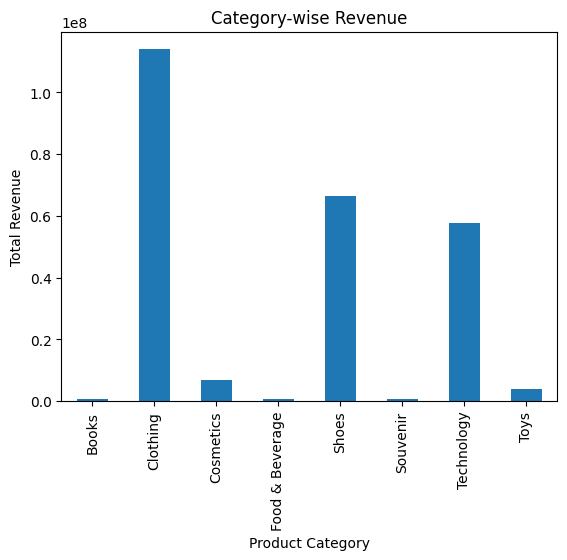

In [ ]:
# DATA VISUALIZATION

# Bar chart: Category-wise revenue
category_revenue.plot(kind="bar")

plt.title("Category-wise Revenue")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")

plt.show()

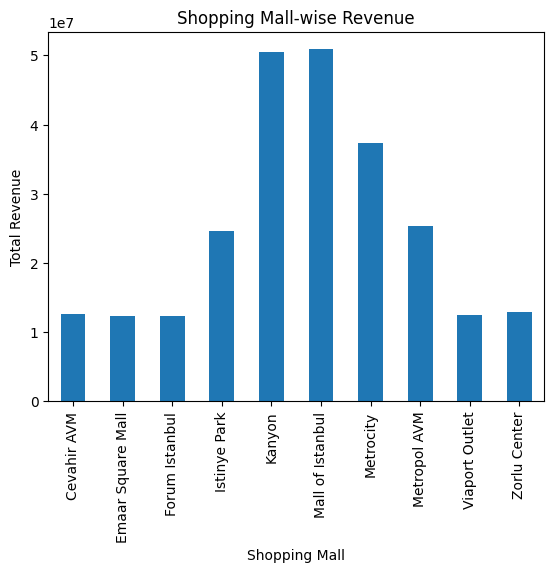

In [ ]:
# Bar chart: Shopping mall-wise revenue
mall_sales.plot(kind="bar")

plt.title("Shopping Mall-wise Revenue")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Revenue")

plt.show()

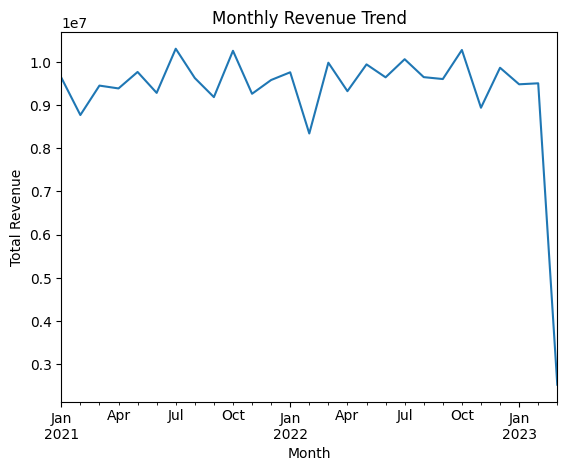

In [ ]:
# Line chart: Monthly revenue trend
monthly_sales.plot(kind="line")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.show()


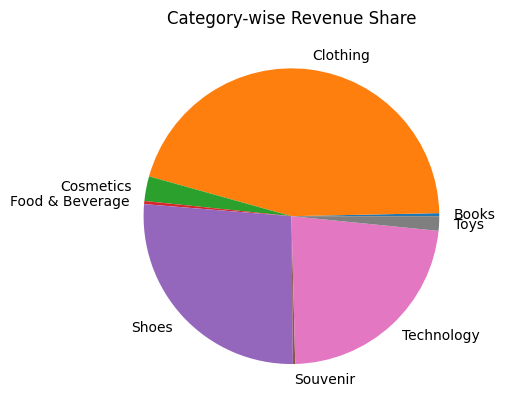

In [ ]:
# Pie chart: Category-wise revenue share
category_revenue.plot(kind="pie")

plt.title("Category-wise Revenue Share")
plt.ylabel("")

plt.show()


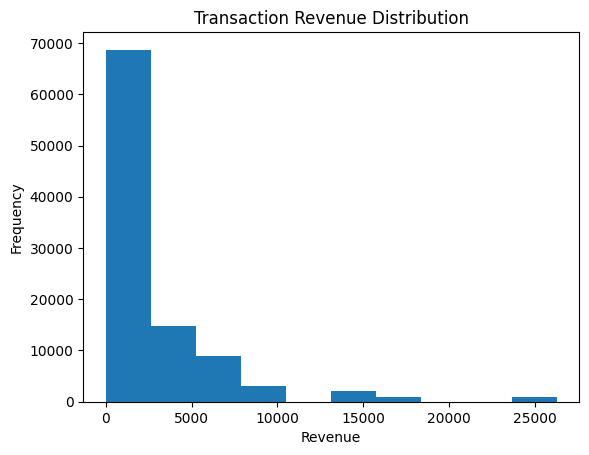

In [ ]:
# Histogram: Transaction revenue Distribution
df["revenue"].plot(kind="hist")

plt.title("Transaction Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# INSIGHTS
# Highest revenue category
best_category = category_revenue.idxmax()

# Lowest revenue category
lowest_category = category_revenue.idxmin()

# Highest revenue shopping mall
best_mall = mall_sales.idxmax()

# Highest revenue month
best_month = monthly_sales.idxmax()

print("----- SALES ANALYSIS INSIGHTS -----")

print(best_category)

print(lowest_category)

print(best_mall)

print(best_month)

print(total_revenue)

print(total_quantity)

----- SALES ANALYSIS INSIGHTS -----
Clothing
Souvenir
Mall of Istanbul
2021-07
251505794.25000003
298712


In [ ]:
df.to_csv('sales_data_cleaned.csv', index=False)
print("File Saved")

File Saved
